# 06. Target Metric Behavior, Leakage Audit & Handoff to Role 3

> **Role**: Role 2 — Dataset Collection & EDA  
> **Project**: Project 18 — Water Quality Prediction via Gradient Boosting & DNN  
> **Course**: Semester 5 AML / DL  

Analyzes target distributions, documents the CCME mathematical index formula, warns against deterministic leakage, and provides clear 70/15/15 Stratified Split Guidelines for Role 3.

---

## 1. Setup & Environment

In [1]:
# Setup and Load Data
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
DATA_PATH = 'data/Dataset/Parquet/Combined Data/Combined_dataset.parquet'
OUT_DIR = 'data/GeneratedOutput/01.EDA'
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join('..', '..', DATA_PATH)
    OUT_DIR = os.path.join('..', '..', OUT_DIR)
os.makedirs(OUT_DIR, exist_ok=True)
df = pd.read_parquet(DATA_PATH)
print(f"Loaded master dataset: {len(df):,} records.")

Loaded master dataset: 4,297,895 records.


## 2. Continuous Target Distribution: `CCME_Values`
Audits regression target shape, identifying the pronounced peak at 100.0 (pristine water with zero exceedances).

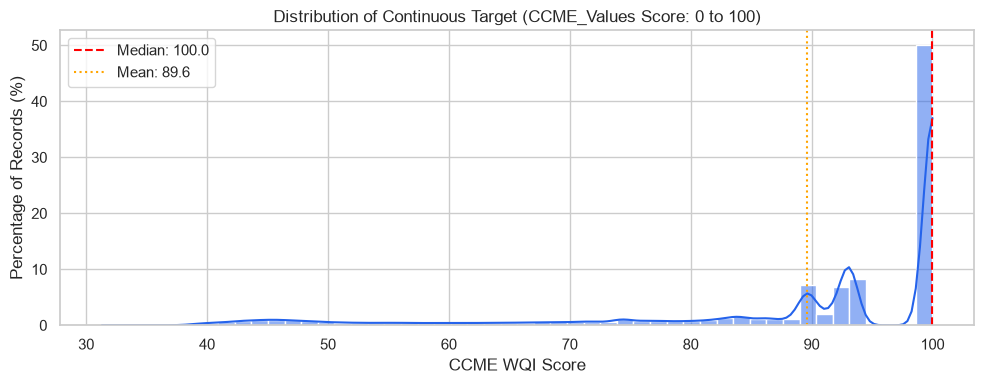

,Quantile,CCME Score
0,0.01,41.798063
1,0.05,48.079863
2,0.10,63.103013
3,0.25,88.269116
4,0.50,100.000000
5,0.75,100.000000
6,0.90,100.000000
7,0.95,100.000000
8,0.99,100.000000


In [2]:
# Target Regression Distribution
plt.figure(figsize=(10, 4))
sns.histplot(df['CCME_Values'], bins=50, kde=True, color='#2563eb', stat='percent')
plt.title('Distribution of Continuous Target (CCME_Values Score: 0 to 100)')
plt.xlabel('CCME WQI Score')
plt.ylabel('Percentage of Records (%)')
plt.axvline(df['CCME_Values'].median(), color='red', linestyle='--', label=f'Median: {df["CCME_Values"].median():.1f}')
plt.axvline(df['CCME_Values'].mean(), color='orange', linestyle=':', label=f'Mean: {df["CCME_Values"].mean():.1f}')
plt.legend()
plt.tight_layout()
plt.show()

percentiles = df['CCME_Values'].quantile([0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
pd.DataFrame({'Quantile': percentiles.index, 'CCME Score': percentiles.values})

## 3. Categorical Target Distribution: `CCME_WQI` Class Imbalance
Visualizes the class imbalance across Excellent, Good, Fair, Marginal, and Poor.

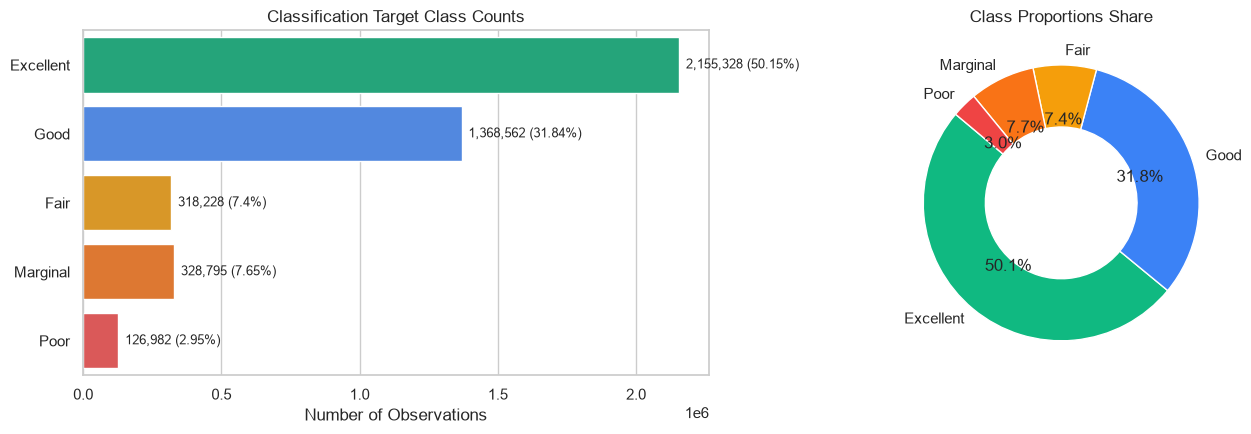

,Class,Count,Percentage (%)
0,Excellent,2155328,50.15
1,Good,1368562,31.84
2,Fair,318228,7.40
3,Marginal,328795,7.65
4,Poor,126982,2.95


In [3]:
# Classification Class Imbalance
wqi_counts = df['CCME_WQI'].value_counts()
wqi_pcts = (wqi_counts / len(df) * 100).round(2)
order = ['Excellent', 'Good', 'Fair', 'Marginal', 'Poor']

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Bar Chart
sns.barplot(x=wqi_counts[order].values, y=order, palette=['#10b981', '#3b82f6', '#f59e0b', '#f97316', '#ef4444'], ax=axes[0], hue=order, legend=False)
axes[0].set_title('Classification Target Class Counts')
axes[0].set_xlabel('Number of Observations')
for i, v in enumerate(wqi_counts[order].values):
    axes[0].text(v + 25000, i, f'{v:,} ({wqi_pcts[order].iloc[i]}%)', va='center', fontsize=9)

# Donut Chart
axes[1].pie(wqi_counts[order].values, labels=order, autopct='%1.1f%%', startangle=140,
           colors=['#10b981', '#3b82f6', '#f59e0b', '#f97316', '#ef4444'], wedgeprops=dict(width=0.45, edgecolor='w'))
axes[1].set_title('Class Proportions Share')

plt.tight_layout()
plt.show()

pd.DataFrame({'Class': order, 'Count': wqi_counts[order].values, 'Percentage (%)': wqi_pcts[order].values})

## 4. AML / DL Target Leakage Audit
Crucial for academic evaluation: deconstructs the CCME mathematical formula and explains why naive models can experience deterministic leakage.

In [4]:
# Target Leakage Audit
leakage_explanation = pd.DataFrame({
    'Aspect': [
        'CCME Mathematical Definition',
        'Scope (F1)',
        'Frequency (F2)',
        'Amplitude (F3)',
        'Leakage Risk in AML/DL',
        'Legitimate Prediction Task'
    ],
    'Technical Description': [
        'WQI = 100 - (sqrt(F1^2 + F2^2 + F3^2) / 1.732)',
        'Percentage of parameters exceeding threshold: (Failed Params / Total Params) * 100',
        'Percentage of failed tests: (Failed Tests / Total Tests) * 100',
        'Normalized sum of excursions: nse / (0.01*nse + 0.01)',
        'If a model is fed all 8 parameters with zero noise, it merely learns an algebraic formula rather than environmental dynamics.',
        'Predicting WQI from sparse subsets (e.g. only physical probes Temp+pH+DO) or forecasting future WQI from past conditions.'
    ]
})
leakage_explanation

,Aspect,Technical Description
0,CCME Mathematical Definition,WQI = 100 - (sqrt(F1^2 + F2^2 + F3^2) / 1.732)
1,Scope (F1),Percentage of parameters exceeding threshold: ...
2,Frequency (F2),Percentage of failed tests: (Failed Tests / To...
3,Amplitude (F3),Normalized sum of excursions: nse / (0.01*nse ...
4,Leakage Risk in AML/DL,If a model is fed all 8 parameters with zero n...
5,Legitimate Prediction Task,Predicting WQI from sparse subsets (e.g. only ...


## 5. Formal Handoff to Role 3: 70 / 15 / 15 Splitting Guidelines
Specifications for the Preprocessing & Feature Engineering teammate to split data cleanly without leakage.

In [5]:
# Export Splitting Guidelines Parquet
split_spec = pd.DataFrame({
    'Split': ['Training Set (70%)', 'Validation Set (15%)', 'Test Set (15%)'],
    'Approximate Rows': [
        f"{int(len(df) * 0.70):,}",
        f"{int(len(df) * 0.15):,}",
        f"{int(len(df) * 0.15):,}"
    ],
    'Stratification Strategy': [
        'Stratified across Country, Waterbody Type, and CCME_WQI',
        'Stratified across Country, Waterbody Type, and CCME_WQI',
        'Stratified across Country, Waterbody Type, and CCME_WQI'
    ],
    'Purpose': [
        'Model parameter learning (XGBoost, Random Forest, MLP)',
        'Hyperparameter tuning, early stopping, threshold calibration',
        'Final unbiased generalizability evaluation (MAE, RMSE, R2, Macro F1)'
    ]
})

out_path = os.path.join(OUT_DIR, '06_target_audit_and_splitting_guidelines.parquet')
split_spec.to_parquet(out_path, index=False, compression='snappy')
print(f"Exported Splitting Guidelines to: {out_path} ({os.path.getsize(out_path)} bytes)")
split_spec

Exported Splitting Guidelines to: data/GeneratedOutput/01.EDA/06_target_audit_and_splitting_guidelines.parquet (3618 bytes)


,Split,Approximate Rows,Stratification Strategy,Purpose
0,Training Set (70%),"3,008,526","Stratified across Country, Waterbody Type, and...","Model parameter learning (XGBoost, Random Fore..."
1,Validation Set (15%),"644,684","Stratified across Country, Waterbody Type, and...","Hyperparameter tuning, early stopping, thresho..."
2,Test Set (15%),"644,684","Stratified across Country, Waterbody Type, and...",Final unbiased generalizability evaluation (MA...
